# Задание 2. Что меняется, когда один класс повторяется

Сначала создаём три группы по 1 000 точек с четырьмя признаками.
Для границ берём только классы 0 и 1 и первые два признака. Затем
увеличиваем число копий класса 0. Координаты точек остаются прежними,
меняется вес класса в обучении и в расчёте метрик.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="ticks")
SEED = 42

In [2]:
def inspect_data(raw, features, target="class"):
    df = raw.dropna(subset=[*features, target]).copy()
    display(pd.DataFrame({
        "исходные строки": [len(raw)],
        "исходные столбцы": [raw.shape[1]],
        "исходные признаки": [raw.shape[1] - 1],
        "выбранные признаки": [len(features)],
        "классы": [raw[target].nunique()],
        "строки с пропусками, %": [100 * raw.isna().any(axis=1).mean()],
        "строки после очистки": [len(df)],
    }))
    display(pd.concat(
        [raw[target].value_counts().rename("до"), df[target].value_counts().rename("после")],
        axis=1,
    ).sort_index())
    display(df[features].describe().round(3))
    for label, subset in [("Вся выборка", df), *df.groupby(target, sort=True)]:
        display(subset[features].corr(method="pearson").round(3)
                .style.set_caption(f"Корреляция Пирсона · {label}"))
    return df

def pairplot(df, features, target="class"):
    classes = sorted(df[target].unique())
    graph = sns.pairplot(
        df, vars=features, hue=target, markers=["o", "s", "^", "D", "v", "P", "X"][:len(classes)],
        diag_kind="hist", diag_kws={"bins": 20, "element": "step", "fill": False},
        plot_kws={"alpha": 0.55, "s": 12, "linewidth": 0}, height=1.75,
    )
    graph.fig.set_dpi(95)
    plt.show()

,исходные строки,исходные столбцы,исходные признаки,выбранные признаки,классы,"строки с пропусками, %",строки после очистки
0,3000,5,4,4,3,0.0,3000


,до,после
class,,
0,1000,1000
1,1000,1000
2,1000,1000


,x1,x2,x3,x4
count,3000.000,3000.000,3000.000,3000.000
mean,0.016,0.982,-0.697,0.675
std,1.291,1.772,1.596,1.613
min,-4.020,-3.396,-5.922,-4.688
25%,-0.880,-0.362,-1.904,-0.524
50%,-0.023,0.700,-0.839,0.819
75%,0.931,2.411,0.488,1.895
max,4.098,5.993,4.077,4.926


,x1,x2,x3,x4
x1,1.000000,0.119000,0.318000,-0.338000
x2,0.119000,1.000000,-0.372000,0.352000
x3,0.318000,-0.372000,1.000000,-0.608000
x4,-0.338000,0.352000,-0.608000,1.000000


,x1,x2,x3,x4
x1,1.000000,0.008000,-0.038000,-0.023000
x2,0.008000,1.000000,-0.032000,0.005000
x3,-0.038000,-0.032000,1.000000,0.034000
x4,-0.023000,0.005000,0.034000,1.000000


,x1,x2,x3,x4
x1,1.000000,-0.055000,0.012000,0.014000
x2,-0.055000,1.000000,0.016000,-0.049000
x3,0.012000,0.016000,1.000000,-0.011000
x4,0.014000,-0.049000,-0.011000,1.000000


,x1,x2,x3,x4
x1,1.000000,0.022000,-0.009000,-0.026000
x2,0.022000,1.000000,0.009000,-0.031000
x3,-0.009000,0.009000,1.000000,-0.022000
x4,-0.026000,-0.031000,-0.022000,1.000000


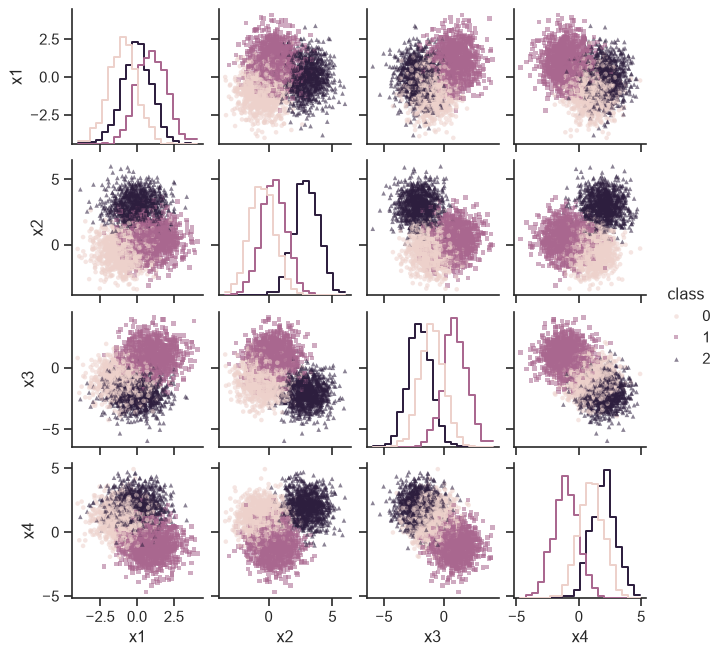

In [3]:
from sklearn.datasets import make_blobs
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import auc, precision_recall_curve, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.svm import SVC

features = [f"x{i}" for i in range(1, 5)]
X, labels = make_blobs(
    n_samples=[1000] * 3, centers=[[-1, -0.5, -1, 1], [1, 0.5, 1, -1], [0, 3, -2, 2]],
    cluster_std=1.0, random_state=SEED,
)
df1 = inspect_data(pd.DataFrame(X, columns=features).assign(**{"class": labels}), features)
pairplot(df1, features)

## Как хранятся копии

В df5 каждая точка класса 0 считается пять раз, а точка любого другого
класса — один раз. Поэтому в таблице числа объектов будут 5 000,
1 000 и 1 000. В коде одна строка с весом 5 заменяет пять одинаковых строк.
Так df10k умещается в памяти, хотя при буквальном повторении у него было
бы 10 002 000 строк.

В LDA вес участвует в расчёте доли класса и общей внутриклассовой
ковариации. В SVM он увеличивает штраф за ошибку на этой точке.
Проверка в конце ячейки сравнивает функцию LDA с результатом
на буквально повторённых строках df5.

Для проверки модели делим исходные точки до учёта весов. Если бы сначала
размножили строки, копии одной точки могли бы оказаться и в обучении,
и в тесте.

In [4]:
repetitions = [1, 2, 5, 10, 20, 50, 100, 1000, 10_000]
def weights(y, copies):
    return np.where(y == 0, copies, 1)

datasets = {
    f"df{copies if copies != 10_000 else '10k'}":
    df1.assign(multiplicity=weights(df1["class"], copies))
    for copies in repetitions
}
counts = pd.DataFrame({
    name: data.groupby("class")["multiplicity"].sum() for name, data in datasets.items()
}).T
display(counts)
assert counts.loc["df10k"].tolist() == [10_000_000, 1000, 1000]

binary = df1.loc[df1["class"].isin([0, 1])]
points = binary[features[:2]].to_numpy()
y = binary["class"].to_numpy()

def fit_lda(X, y, sample_weight):
    means = np.stack([np.average(X[y == label], weights=sample_weight[y == label], axis=0)
                      for label in (0, 1)])
    class_counts = np.bincount(y, weights=sample_weight, minlength=2)
    centered = X - means[y]
    covariance = centered.T @ (centered * sample_weight[:, None]) / class_counts.sum()
    coef = np.linalg.solve(covariance, means[1] - means[0])
    intercept = np.log(class_counts[1] / class_counts[0]) - means.mean(axis=0) @ coef
    return coef, intercept

def lda_score(X, fitted):
    coef, intercept = fitted
    return X @ coef + intercept

# Проверка против LDA на явных повторах, включая смещение.
w = weights(y, 5)
reference = LinearDiscriminantAnalysis(solver="lsqr").fit(np.repeat(points, w, axis=0), np.repeat(y, w))
np.testing.assert_allclose(lda_score(points, fit_lda(points, y, w)),
                           reference.decision_function(points), atol=1e-10)

class,0,1,2
df1,1000,1000,1000
df2,2000,1000,1000
df5,5000,1000,1000
df10,10000,1000,1000
df20,20000,1000,1000
df50,50000,1000,1000
df100,100000,1000,1000
df1000,1000000,1000,1000
df10k,10000000,1000,1000


## Сравнение границ LDA и SVM

На всех панелях одинаковые оси. Синим показана зона класса 0, красным —
класса 1, чёрным — граница. Копии ложатся в ту же точку, поэтому визуально
число кружков и треугольников не растёт.

Сравни первый и последний рисунки для LDA. При большом весе класса 0
синяя область занимает почти всё облако. У SVM граница изгибается,
поскольку используется RBF-ядро. Его настройки в эксперименте фиксированы.

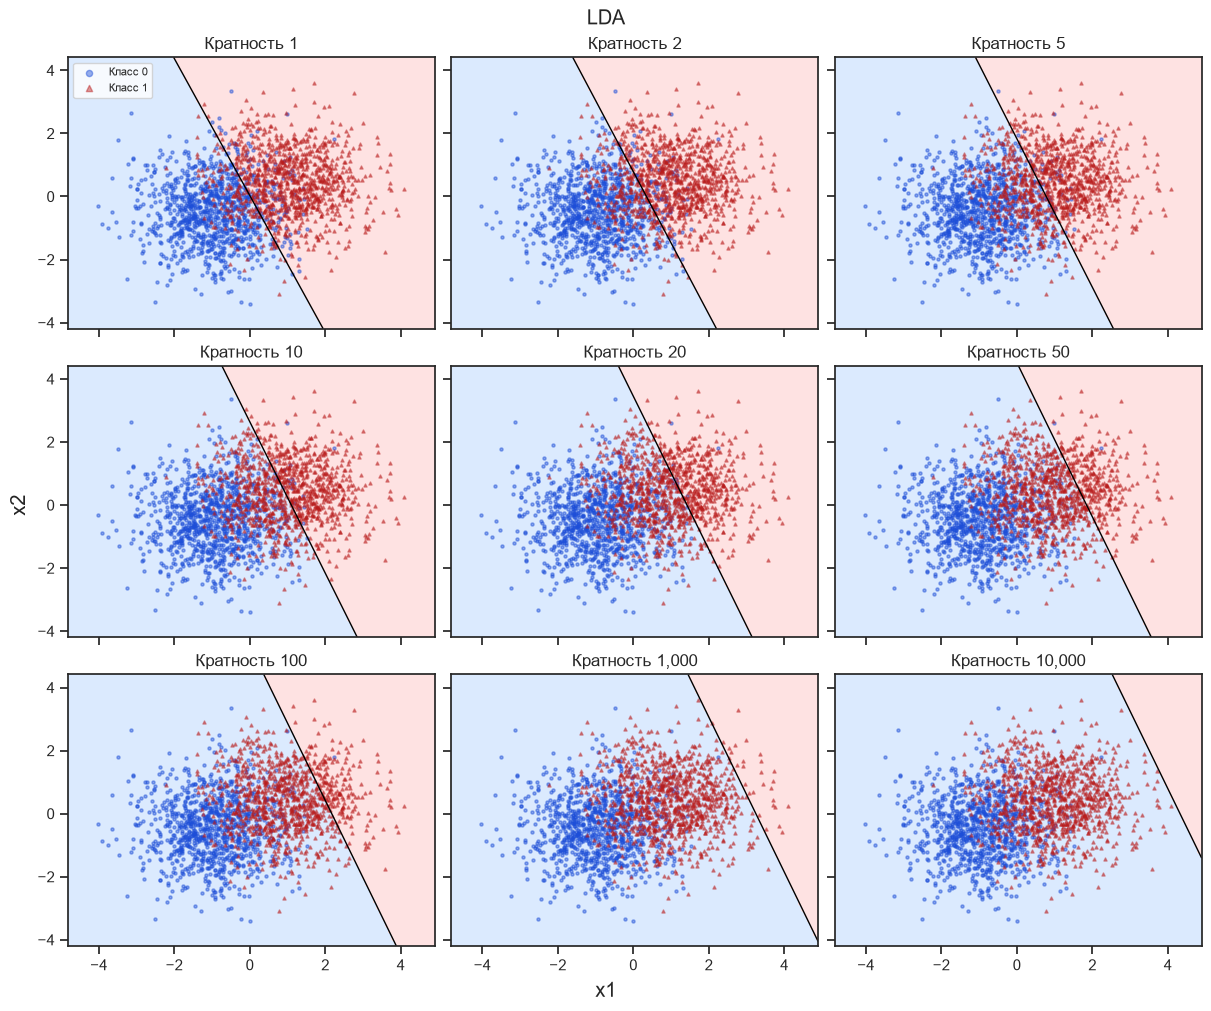

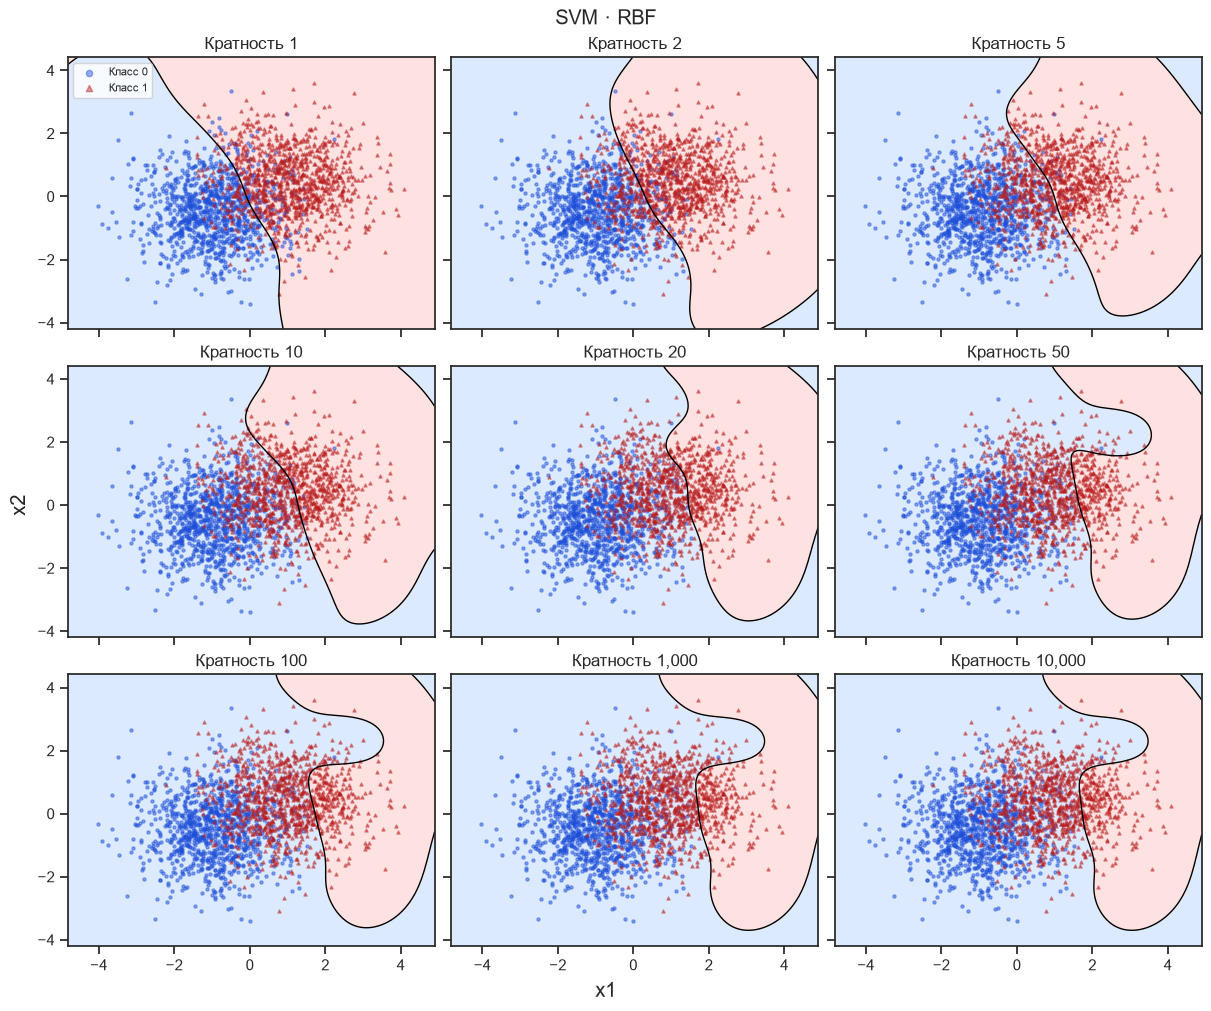

In [5]:
limits = [(column.min() - 0.8, column.max() + 0.8) for column in points.T]
xx, yy = np.meshgrid(*(np.linspace(*lim, 125) for lim in limits))
grid = np.c_[xx.ravel(), yy.ravel()]
lda_models = {}
svm_models = {}
for copies in repetitions:
    w = weights(y, copies)
    lda_models[copies] = fit_lda(points, y, w)
    svm_models[copies] = SVC(C=1.0, gamma=0.5).fit(points, y, sample_weight=w)

def boundary_panel(score, title):
    fig, axes = plt.subplots(3, 3, figsize=(12, 10), sharex=True, sharey=True, layout="constrained")
    for ax, copies in zip(axes.flat, repetitions):
        values = score(copies).reshape(xx.shape)
        ax.contourf(xx, yy, values >= 0, levels=[-0.5, 0.5, 1.5],
                    colors=["#dbeafe", "#fee2e2"])
        if values.min() < 0 < values.max():
            ax.contour(xx, yy, values, levels=[0], colors="black", linewidths=1.0)
        for label, marker, color in [(0, "o", "#1d4ed8"), (1, "^", "#b91c1c")]:
            ax.scatter(*points[y == label].T, c=color, marker=marker, s=5, alpha=0.45,
                       label=f"Класс {label}")
        ax.set_title(f"Кратность {copies:,}")
    axes[0, 0].legend(markerscale=2, fontsize=8)
    fig.supxlabel("x1")
    fig.supylabel("x2")
    fig.suptitle(title)
    plt.show()

boundary_panel(lambda copies: lda_score(grid, lda_models[copies]), "LDA")
boundary_panel(lambda copies: svm_models[copies].decision_function(grid), "SVM · RBF")

## Три точки на отрезке между центрами

1. **Середина** даёт одинаковый вес обоим центрам классов. Она остаётся на месте,
   потому что одинаковое повторение всех точек класса не меняет его центр.
2. **Общий центр** усредняет все точки с их весами. Он сдвигается к центру
   класса 0 по мере роста числа копий.
3. **Пересечение** — место, где решающая функция LDA равна нулю на этом
   отрезке. Записываем координаты точки как m₀ + t(m₁ − m₀). Параметр
   t=0 даёт первый центр, t=1 — второй. Значение вне этого диапазона
   означает, что граница проходит за пределами отрезка.

При кратности 20 и выше в таблице пересечения стоит NaN. Поэтому линия
пересечения на графике обрывается после кратности 10.

,середина x1,середина x2,общий центр x1,общий центр x2,пересечение x1,пересечение x2
кратность,,,,,,
1,0.0266,-0.0219,0.0266,-0.0219,0.0266,-0.0219
2,0.0266,-0.0219,-0.3054,-0.1730,0.3041,0.1045
5,0.0266,-0.0219,-0.6374,-0.3241,0.6665,0.2694
10,0.0266,-0.0219,-0.7883,-0.3928,0.9390,0.3934
20,0.0266,-0.0219,-0.8745,-0.4320,NaN,NaN
50,0.0266,-0.0219,-0.9303,-0.4574,NaN,NaN
100,0.0266,-0.0219,-0.9497,-0.4662,NaN,NaN
1000,0.0266,-0.0219,-0.9674,-0.4743,NaN,NaN
10000,0.0266,-0.0219,-0.9692,-0.4751,NaN,NaN


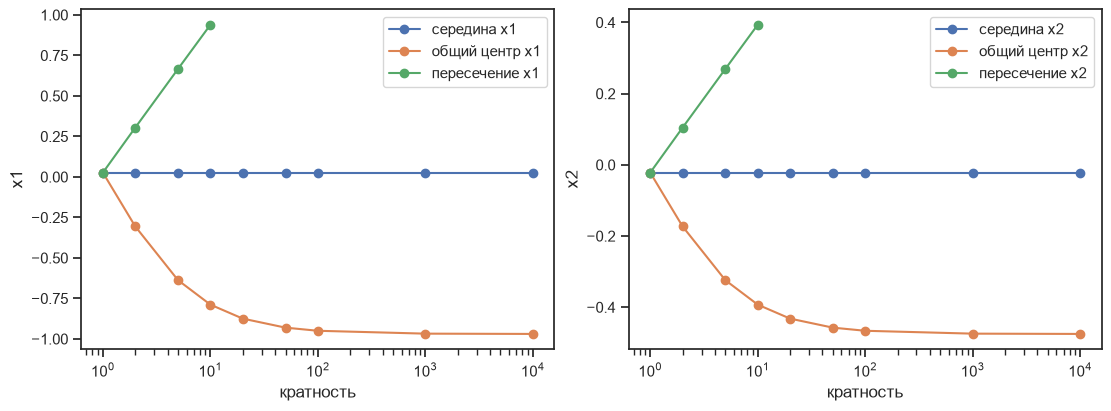

In [6]:
centers = np.stack([points[y == label].mean(axis=0) for label in (0, 1)])
geometry = []
for copies in repetitions:
    fitted = lda_models[copies]
    f0, f1 = lda_score(centers, fitted)
    t = -f0 / (f1 - f0)
    intersection = centers[0] + t * (centers[1] - centers[0]) if 0 <= t <= 1 else [np.nan] * 2
    geometry.append([copies, *centers.mean(axis=0),
                     *np.average(points, axis=0, weights=weights(y, copies)), *intersection])
geometry = pd.DataFrame(
    geometry, columns=["кратность", "середина x1", "середина x2", "общий центр x1",
                       "общий центр x2", "пересечение x1", "пересечение x2"],
).set_index("кратность")
display(geometry.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, coordinate in zip(axes, ("x1", "x2")):
    geometry.filter(like=coordinate).plot(ax=ax, logx=True, marker="o", ylabel=coordinate)
plt.show()

## ROC, PR и PR-Gain

На ROC горизонтальная ось показывает долю ложных срабатываний
среди отрицательных объектов, вертикальная — долю найденных среди
положительных.
PR отвечает на два других вопроса. Сколько объектов нужного класса
мы нашли (recall) и сколько среди найденных действительно принадлежат
этому классу (precision)?

В df10k класс 1 составляет примерно 0,01% бинарного набора. Одно ложное
срабатывание на исходной точке класса 0 засчитывается как 10 000 ошибок
и резко снижает precision. Посмотри на строки для положительного
класса 1. AUROC держится около 0,94, а AUPRC падает с 0,936 до 0,186.

Затем меняем положительный класс и знак оценки. Для PR это существенно,
потому что базовый уровень равен доле положительного класса. В PR-Gain
доля класса учитывается в формулах обеих осей, и базовая линия проходит
через ноль. Для площади берём часть от Recall Gain = 0. Формулы и
определение кривой приведены у [Flach и Kull](https://proceedings.neurips.cc/paper_files/paper/2015/file/33e8075e9970de0cfea955afd4644bb2-Paper.pdf).

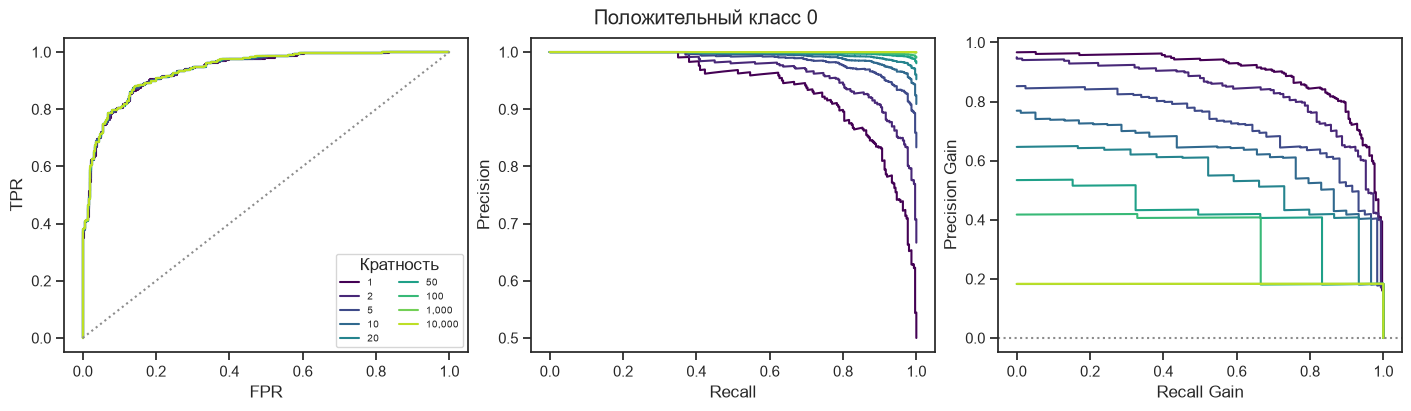

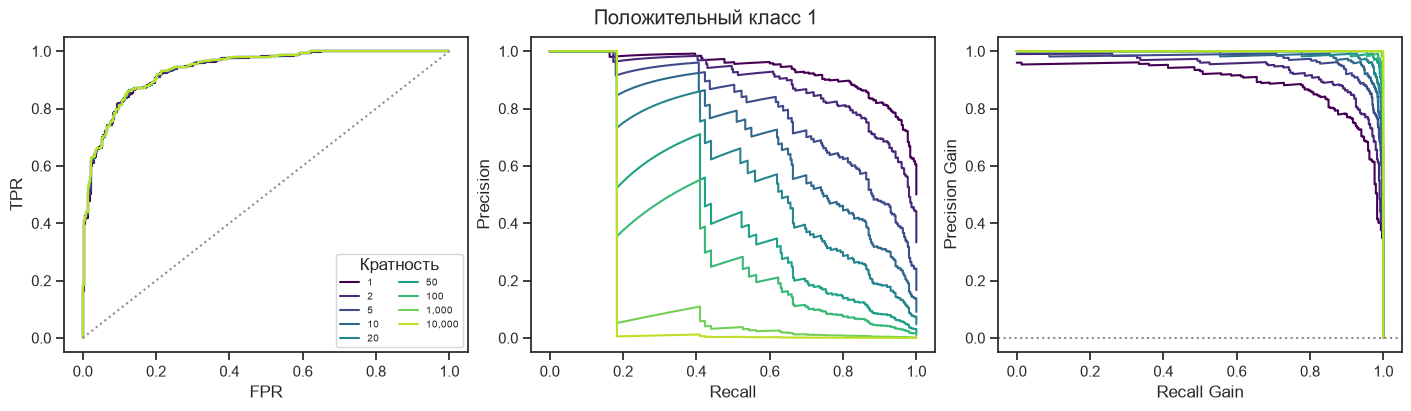

,класс,кратность,доля класса,AUROC,AUPRC,AUPRG
0,0,1,0.50000,0.93628,0.93898,0.89647
1,0,2,0.66667,0.93712,0.96692,0.83614
2,0,5,0.83333,0.93771,0.98599,0.72443
3,0,10,0.90909,0.93792,0.99285,0.62330
4,0,20,0.95238,0.93816,0.99640,0.53802
5,0,50,0.98039,0.93836,0.99855,0.41407
6,0,100,0.99010,0.93841,0.99927,0.33554
7,0,1000,0.99900,0.93849,0.99993,0.18292
8,0,10000,0.99990,0.93852,0.99999,0.18329
9,1,1,0.50000,0.93628,0.93595,0.89329


In [7]:
def pr_gain(truth, scores, w):
    fpr, tpr, _ = roc_curve(truth, scores, sample_weight=w, drop_intermediate=False)
    prevalence = np.average(truth, weights=w)
    crossing = np.searchsorted(tpr, prevalence)
    if tpr[crossing] > prevalence:
        fraction = (prevalence - tpr[crossing - 1]) / (tpr[crossing] - tpr[crossing - 1])
        fpr_at_crossing = fpr[crossing - 1] + fraction * (fpr[crossing] - fpr[crossing - 1])
        fpr = np.r_[fpr_at_crossing, fpr[crossing:]]
        tpr = np.r_[prevalence, tpr[crossing:]]
    else:
        fpr, tpr = fpr[crossing:], tpr[crossing:]
    recall_gain = (tpr - prevalence) / ((1 - prevalence) * tpr)
    precision_gain = 1 - fpr / tpr
    return recall_gain, precision_gain

indices = np.arange(len(y))
train, test = train_test_split(indices, test_size=0.30, stratify=y, random_state=SEED)
results = []
for positive in (0, 1):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(repetitions)))
    for copies, color in zip(repetitions, colors):
        w = weights(y, copies)
        model = fit_lda(points[train], y[train], w[train])
        score = lda_score(points[test], model) * (1 if positive == 1 else -1)
        truth = y[test] == positive
        fpr, tpr, _ = roc_curve(truth, score, sample_weight=w[test])
        precision, recall, _ = precision_recall_curve(truth, score, sample_weight=w[test])
        rg, pg = pr_gain(truth, score, w[test])
        results.append([positive, copies, np.average(truth, weights=w[test]),
                        auc(fpr, tpr), auc(recall, precision), auc(rg, pg)])
        for ax, x, values in zip(axes, (fpr, recall, rg), (tpr, precision, pg)):
            ax.plot(x, values, color=color, label=f"{copies:,}")
    axes[0].plot([0, 1], [0, 1], ":", c="0.55")
    axes[2].axhline(0, c="0.55", linestyle=":")
    for ax, xlabel, ylabel in zip(axes, ["FPR", "Recall", "Recall Gain"],
                                  ["TPR", "Precision", "Precision Gain"]):
        ax.set(xlabel=xlabel, ylabel=ylabel)
    axes[0].legend(title="Кратность", fontsize=7, ncol=2)
    fig.suptitle(f"Положительный класс {positive}")
    plt.show()
display(pd.DataFrame(results, columns=["класс", "кратность", "доля класса",
                                       "AUROC", "AUPRC", "AUPRG"]).round(5))

## Кросс-валидация и интервалы для df10k

При 5-fold, например, делим исходные точки на пять частей. По очереди
откладываем одну часть, обучаем LDA на четырёх остальных и предсказываем
отложенную. В результате каждая точка получила прогноз от модели,
которая её не видела. Вес точки учитываем при обучении и оценке.

Для полосы на графике 1 000 раз выбираем с возвращением исходные точки
внутри каждого класса. Используем уже полученные прогнозы и веса.
Полоса показывает, как меняется кривая при таком пересчёте на новом
составе теста. Повторное обучение в бутстрепе здесь не выполняется.

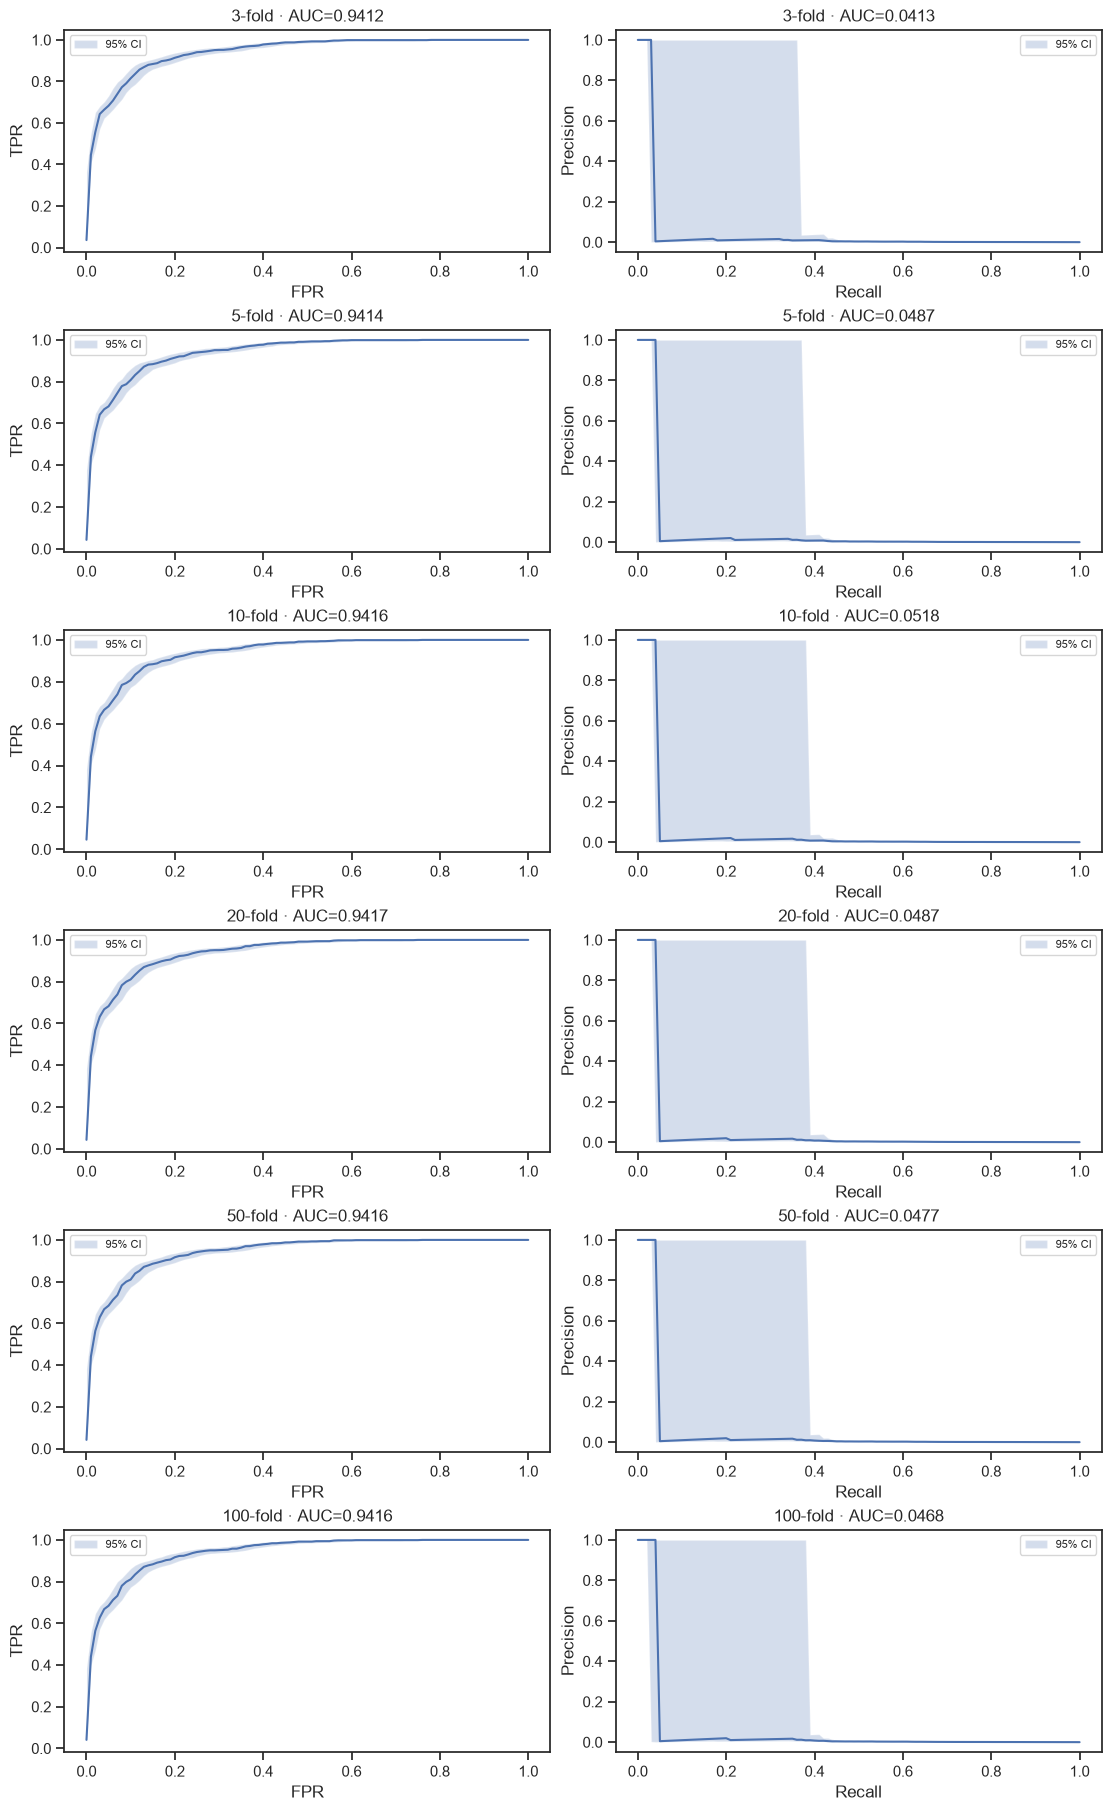

,k,AUROC,"ROC 2,5%","ROC 97,5%",AUPRC,"PR 2,5%","PR 97,5%"
0,3,0.94125,0.93143,0.95038,0.04130,0.03087,0.36766
1,5,0.94136,0.93167,0.95065,0.04871,0.03711,0.37826
2,10,0.94164,0.93187,0.95094,0.05184,0.03977,0.38559
3,20,0.94169,0.93200,0.95090,0.04872,0.03702,0.38661
4,50,0.94160,0.93188,0.95085,0.04772,0.03636,0.38534
5,100,0.94160,0.93191,0.95082,0.04675,0.03565,0.38605


In [8]:
axis_grid = np.linspace(0, 1, 101)
w = weights(y, 10_000)

def curve_summary(y, scores, sample_weight):
    fpr, tpr, _ = roc_curve(y, scores, sample_weight=sample_weight, drop_intermediate=False)
    precision, recall, _ = precision_recall_curve(y, scores, sample_weight=sample_weight)
    return (np.interp(axis_grid, fpr, tpr), np.interp(axis_grid, recall[::-1], precision[::-1]),
            auc(fpr, tpr), auc(recall, precision))

fig, axes = plt.subplots(6, 2, figsize=(11, 18), layout="constrained")
summary = []
groups = [indices[y == label] for label in (0, 1)]
for k, (roc_ax, pr_ax) in zip([3, 5, 10, 20, 50, 100], axes):
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    oof = np.empty(len(y))
    for tr, te in cv.split(points, y):
        oof[te] = lda_score(points[te], fit_lda(points[tr], y[tr], w[tr]))
    roc, pr, auroc, auprc = curve_summary(y, oof, w)
    rng = np.random.default_rng(SEED)
    boot = []
    for _ in range(1000):
        sample = np.concatenate([rng.choice(group, size=len(group)) for group in groups])
        boot.append(curve_summary(y[sample], oof[sample], w[sample]))
    intervals = [np.percentile(np.stack(part), [2.5, 97.5], axis=0) for part in zip(*boot)]
    summary.append([k, auroc, *intervals[2], auprc, *intervals[3]])
    for ax, line, interval, xlabel, ylabel, area in [
        (roc_ax, roc, intervals[0], "FPR", "TPR", auroc),
        (pr_ax, pr, intervals[1], "Recall", "Precision", auprc),
    ]:
        ax.plot(axis_grid, line)
        ax.fill_between(axis_grid, *interval, alpha=0.24, label="95% CI")
        ax.set(xlabel=xlabel, ylabel=ylabel, title=f"{k}-fold · AUC={area:.4f}")
        ax.legend(fontsize=8)
plt.show()
display(pd.DataFrame(summary, columns=["k", "AUROC", "ROC 2,5%", "ROC 97,5%",
                                       "AUPRC", "PR 2,5%", "PR 97,5%"]).round(5))

## Что смотреть в результате

Начни с таблицы центров. Середина стоит на месте, а общий центр уходит
влево. Затем сравни столбцы AUROC и AUPRC. В этом опыте высокая AUROC
сохраняется даже при таком дисбалансе, при котором несколько ранних
ложных срабатываний заметно меняют площадь под PR-кривой.